# Homework 5A: “Done—Looks Great!”

**Due Thursday, November 12, 2026, at 11:59 p.m. Central.**

Your manager forwards a notebook from a former colleague with the following note:

> He was very enthusiastic about AI-assisted analysis. Checking the results... not so much. He's since moved on. Please review and finalize the work to make it presentable.
>
> I need your revised notebook by Thursday, November 12, at 11:59 p.m. Central. Plan to spend no more than 3 hours working on this assignment, including reviewing relevant course material, implementing and checking the analysis, and writing your responses. You may continue if needed, but stop after 5 hours of assignment work. Separate study of general Python fundamentals does not count toward this limit; debugging this notebook does. You are not expected to reach the time limit. In your responses to my comments, explain what you finished and checked. For anything unfinished, show your attempt, identify the sticking point, and say what you would try next.

The notebook contains useful work, questionable choices, and unfinished analysis. Your job is to take responsibility for its **validity** (does it answer the question appropriately?), **veracity** (does the code do what it claims?), and **completeness**.

## Your Assignment

**Review, correct, and complete the inherited notebook to produce a defensible analysis of Australian quarterly cement production.** Explain temporal patterns, investigate recent changes in activity, and determine whether a component-based forecast improves on time-only regression.

Use the provided 1990–2009 data. Take the end of **2007 Q4** as the information boundary for the briefing: use history through that date for component estimates, adjustment comparisons, dependence analysis, and model fitting. Evaluate forecasts on the **eight quarters of 2008–2009**.

Adjust the inherited work as appropriate. Add code and Markdown cells where needed. You do not need to reproduce every element from the lectures, implement additional forecast models (except as directed), or write a separate report.

This individual assignment is worth **10 points**. Partial credit is available for sound analysis, correct diagnoses, and meaningful progress, even when a section is unfinished. Make your work and reasoning visible.

You may use lectures, documentation, and AI assistance to understand, implement, and check your work. Your explanations must be your own, and you must be able to explain or revise the code and reasoning. Record material assistance and how you verified it. The original analyst's problem was submitting unchecked work; using assistance does not transfer your responsibility for the result.

References: [11a: decomposition](https://github.com/olearydj/INSY7130/blob/main/lectures/11a-time-series-and-decomposition/11a-time-series-and-decomposition.ipynb), [11b: dependence and differencing](https://github.com/olearydj/INSY7130/blob/main/lectures/11b-autocorrelation-and-stationarity/11b-autocorrelation-and-stationarity.ipynb), and [12a: forecasting](https://github.com/olearydj/INSY7130/blob/main/lectures/12a-basic-forecasting/12a-basic-forecasting.ipynb).

## Reliable Setup and Utilities

The briefing scenario is fictional, but the data are real, from the Australian Bureau of Statistics through the [FPP data collection](https://otexts.com/fpppy/data/aus_production.csv). The extract retains original measurements for 1990–2009 without imputation or seasonal adjustment. Each row is a national quarterly total of Australian Portland cement production, measured in **thousands of tonnes**. Quarter-start dates label whole quarters.

Data attribution and reuse terms: [Cement Production Data](https://github.com/olearydj/INSY7130/blob/main/homework/hw5a/data/README.md).

The supplied data-loading code is correct and is outside the scope of your audit.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

paths = [Path("cement-production.csv"), Path("data/cement-production.csv"),
         Path("content/homework/hw5a/data/cement-production.csv")]
data_url = (
    "https://raw.githubusercontent.com/olearydj/INSY7130/main/"
    "homework/hw5a/data/cement-production.csv"
)
data_source = next((p for p in paths if p.is_file()), data_url)
frame = pd.read_csv(data_source)
frame["quarter"] = pd.to_datetime(frame["quarter"], format="%Y-%m-%d")
cement = frame.set_index("quarter")["production_thousand_tonnes"].astype(float)
assert cement.index.is_unique and cement.index.is_monotonic_increasing
assert cement.index.equals(pd.date_range("1990-01-01", "2009-10-01", freq="QS"))
assert cement.notna().all()
cement = cement.asfreq("QS")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
display(cement.head().to_frame())

,production_thousand_tonnes
quarter,
1990-01-01,1565.0
1990-04-01,1645.0
1990-07-01,1658.0
1990-10-01,1668.0
1991-01-01,1343.0


The following helper functions display supplied results or score already aligned forecasts. They are optional, correct as provided, and outside the scope of your audit. Selecting the analysis data, fitting models, and deciding which evidence is appropriate belong to the inherited analysis you will review and complete.

In [2]:
def show_components(observed, result, title):
    """Plot a fitted classical or STL result against its input series."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout="constrained")
    axes[0].plot(observed.index, observed, color="0.65", label="Observed")
    axes[0].plot(observed.index, result.trend, label="Trend-cycle")
    axes[0].legend()
    for ax, field in zip(axes[1:], ["seasonal", "resid"], strict=True):
        ax.plot(observed.index, getattr(result, field))
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set_title("Seasonal" if field == "seasonal" else "Remainder")
    for ax in axes:
        ax.set_ylabel("Thousand tonnes")
    axes[0].set_title(title)
    axes[-1].set_xlabel("Year")
    plt.show()
    plt.close(fig)


def show_dependence(series, title):
    """Display a series and its sample ACF through eight quarterly lags."""
    values = series.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
    axes[0].plot(values.index, values)
    axes[0].set(title=title, xlabel="Year", ylabel="Thousand tonnes")
    plot_acf(values, lags=8, zero=False, alpha=None, ax=axes[1])
    axes[1].set(title="Sample ACF", xlabel="Lag (quarters)", ylabel="ACF", ylim=(-1, 1))
    plt.show()
    plt.close(fig)


def score_forecasts(actual, predictions):
    """Return metrics and actual-minus-predicted errors for matching date indexes.

    actual is a Series; predictions is a DataFrame with one column per method.
    This checks alignment, not whether model fitting used permissible information.
    """
    if not actual.index.equals(predictions.index):
        raise ValueError("Actuals and predictions must have the same dates in the same order.")
    if actual.isna().any() or predictions.isna().any().any():
        raise ValueError("Every evaluated date needs an actual and each method's prediction.")
    errors = predictions.rsub(actual, axis="index")
    scores = pd.DataFrame({"MAE": errors.abs().mean(),
                           "RMSE": np.sqrt(errors.pow(2).mean()),
                           "Mean error": errors.mean()})
    return scores, errors

## Inherited Notebook: Cement Briefing

This was the last version provided by your former colleague. It came with the note:

> Done. Looks great! The seasonal model tracks production well. Main takeaways are below. AI makes this so easy! ;-P

Your audit covers the inherited analysis from “First Look” through “Draft Recommendation,” including its code, results, and claims. Correct and extend that analysis to address the manager’s feedback. Your response in Draft Recommendation serves as the completed briefing. Comments labeled **Manager’s comment** identify requested follow-up work; the rest is your former colleague’s work as submitted.

Respond to each manager comment where indicated. Explain what you changed or added and how you checked it; identify any original problem or omission. If you retained the existing work, explain why.

### First Look

The series grows over time and first quarters tend to be lower. There is enough regularity here to make a useful forecast.

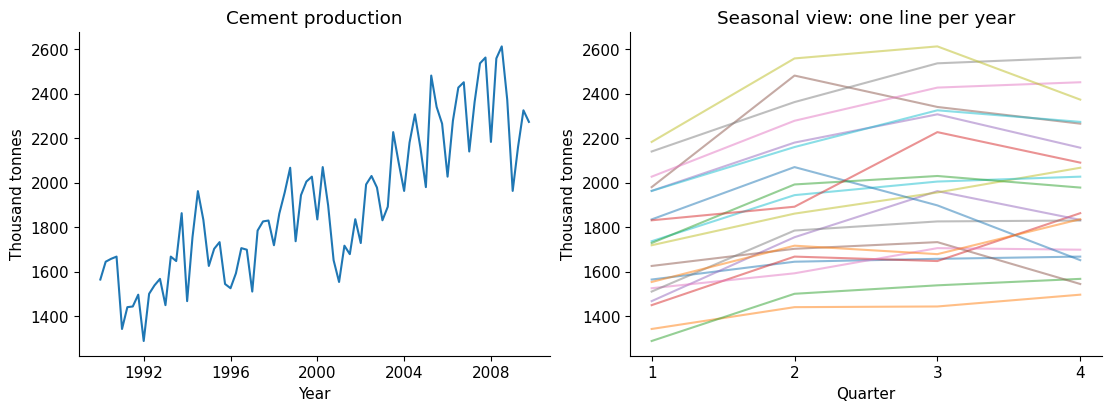

In [3]:
analysis = cement
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(analysis.index, analysis)
axes[0].set(title="Cement production", xlabel="Year", ylabel="Thousand tonnes")
# Group observations by calendar year to draw one seasonal line per year.
for year, values in analysis.groupby(analysis.index.year):
    axes[1].plot(values.index.quarter, values.to_numpy(), alpha=0.5)
axes[1].set(title="Seasonal view: one line per year", xlabel="Quarter",
            ylabel="Thousand tonnes", xticks=[1, 2, 3, 4])
plt.show()
plt.close(fig)

**Manager’s comment:** Describe the main temporal patterns. Which observations support the claim that this series will be useful for forecasting?

> The cement-production series shows several temporal patterns that support forecasting. First, production exhibits a clear long-term upward trend from the early 1990s through approximately 2008, increasing from roughly 1,300-1,600 thousand tonnes per quarter at the beginning of the series to more than 2,400-2,600 thousand tonnes in later years. Although there are short-term fluctuations, production does not behave like random noise and instead follows a persistent underlying pattern over time.
> The seasonal plot indicates a recurring quarterly pattern. Across most years, production is lowest in the first quarter and generally increases through the second and third quarters before remaining high or changing more modestly in the fourth quarter. While the magnitude of the seasonal pattern varies somewhat from year to year, the overall shape is similar across many years, suggesting stable seasonality.
> These characteristics support the claim that the series should be useful for forecasting because:
> 
> 1. The series contains a recognizable trend rather than completely unpredictable variation.
> 2. The quarterly seasonal pattern repeats across years.
> 3. Adjacent observations appear related, indicating temporal dependence rather than independent observations.
> 4. The random fluctuations are relatively small compared with the overall trend and seasonal structure.
> 
> Because forecasting methods work best when future values follow patterns observed in the past, the presence of both a sustained trend and recurring seasonality suggests that meaningful forecasts may be possible. However, forecast usefulness must ultimately be evaluated using withheld future observations rather than visual inspection alone.

### Components / Recent Activity

Using the quarterly cycle, the decomposition separates the underlying level, recurring seasonality, and residual variation.

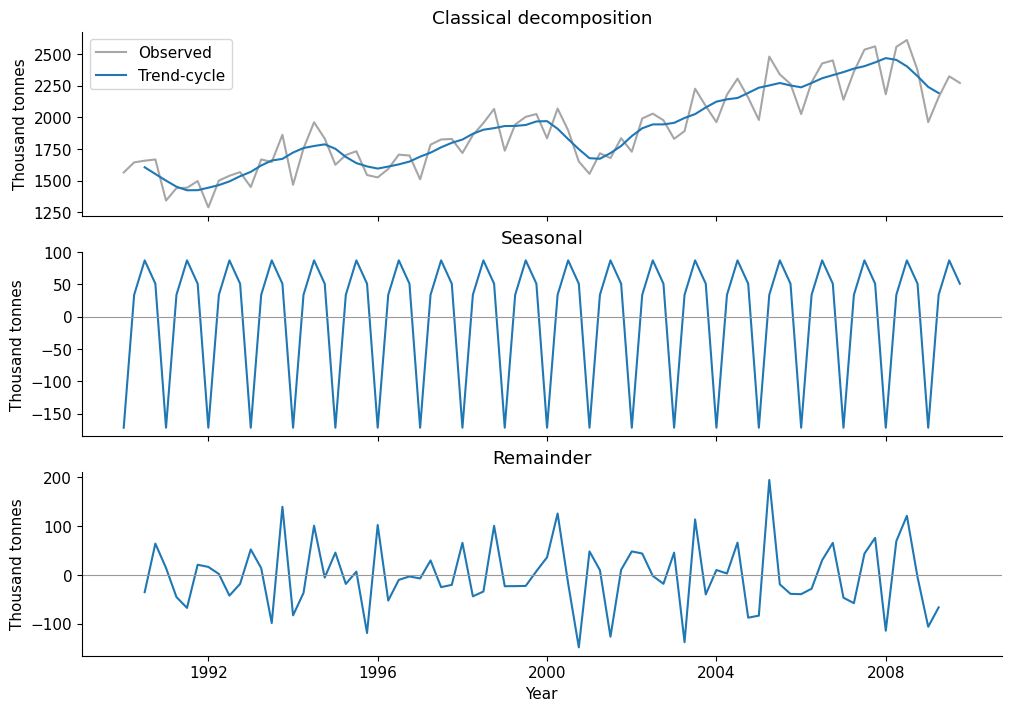

,Quarter effect
quarter,
1,-171.889803
2,33.794408
3,87.103618
4,50.991776


In [5]:
decomposition = seasonal_decompose(analysis, model="additive", period=4)
show_components(analysis, decomposition, "Classical decomposition")

# Direct calculation to check the library's centered trend and seasonal effects.
# These weights center a four-quarter moving average on an observation.
# A complete window needs two observations on either side of its date.
manual_trend = pd.Series(
    np.convolve(analysis.to_numpy(), np.array([1, 2, 2, 2, 1]) / 8, mode="valid"),
    index=analysis.index[2:-2],
)
detrended = analysis.loc[manual_trend.index] - manual_trend
# Average the detrended values for each calendar quarter.
quarter_effects = detrended.groupby(detrended.index.quarter).mean()
# Center the four effects so their mean is zero.
quarter_effects -= quarter_effects.mean()
np.testing.assert_allclose(manual_trend, decomposition.trend.dropna())
display(quarter_effects.rename("Quarter effect").to_frame())

The seasonal pattern represents the same percentage reduction each first quarter, regardless of the production level.

Seasonally adjusted production confirms a substantial decline between late 2006 and early 2007. The downturn is therefore more than the usual first-quarter effect.

In [6]:
adjusted = analysis - decomposition.trend
recent = pd.DataFrame({"Observed": analysis, "Seasonally adjusted": adjusted}).loc[
    "2006-10-01":"2007-04-01"
]
display(recent.round(2))
display(recent.diff().iloc[1:].round(2))

,Observed,Seasonally adjusted
quarter,,
2006-10-01,2451.0,116.50
2007-01-01,2140.0,-218.62
2007-04-01,2362.0,-24.12


,Observed,Seasonally adjusted
quarter,,
2007-01-01,-311.0,-335.12
2007-04-01,222.0,194.50


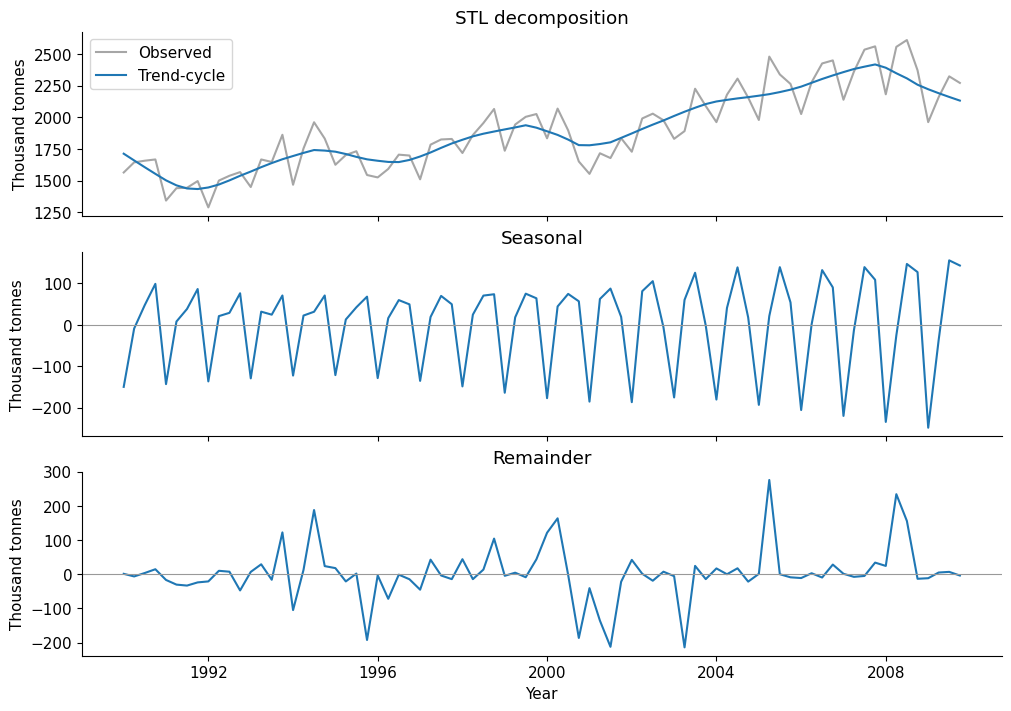

In [7]:
from statsmodels.tsa.seasonal import STL

# STL decomposition requested by the manager
stl = STL(
    analysis,
    period=4,
    seasonal=7,
    robust=True
).fit()

show_components(analysis, stl, "STL decomposition")

In [8]:
# Correct seasonally adjusted series
classical_adjusted = analysis - decomposition.seasonal
stl_adjusted = analysis - stl.seasonal

dates = ["2006-10-01", "2007-01-01"]

comparison = pd.DataFrame({
    "Observed": analysis.loc[dates],
    "Classical adjusted": classical_adjusted.loc[dates],
    "STL adjusted": stl_adjusted.loc[dates]
})

display(comparison.round(2))

changes = comparison.diff().iloc[1]
display(changes.round(2))

observed_change = (
    analysis.loc["2007-01-01"]
    - analysis.loc["2006-10-01"]
)

print(f"Observed change (2006 Q4 -> 2007 Q1): {observed_change:.2f}")

seasonal_compare = pd.DataFrame({
    "Classical seasonal": decomposition.seasonal.loc[dates],
    "STL seasonal": stl.seasonal.loc[dates]
})

display(seasonal_compare.round(2))

summary = pd.DataFrame({
    "Change (thousand tonnes)": [
        analysis.loc["2007-01-01"] - analysis.loc["2006-10-01"],
        classical_adjusted.loc["2007-01-01"] - classical_adjusted.loc["2006-10-01"],
        stl_adjusted.loc["2007-01-01"] - stl_adjusted.loc["2006-10-01"]
    ]
}, index=[
    "Observed",
    "Classical seasonally adjusted",
    "STL seasonally adjusted"
])

display(summary.round(2))

,Observed,Classical adjusted,STL adjusted
quarter,,,
2006-10-01,2451.0,2400.01,2360.54
2007-01-01,2140.0,2311.89,2359.97


Observed             -311.00
Classical adjusted    -88.12
STL adjusted           -0.56
Name: 2007-01-01 00:00:00, dtype: float64

Observed change (2006 Q4 -> 2007 Q1): -311.00


,Classical seasonal,STL seasonal
quarter,,
2006-10-01,50.99,90.46
2007-01-01,-171.89,-219.97


,Change (thousand tonnes)
Observed,-311.00
Classical seasonally adjusted,-88.12
STL seasonally adjusted,-0.56


**Manager’s comment:** Describe the classical decomposition used here and cross-check it with STL using `period=4`, `seasonal=7`, and `robust=True`. Clarify the units of the seasonal effects: does this model describe a constant amount or a constant percentage? Check that the reported adjustment measures what its label claims. Report the observed change from 2006 Q4 to 2007 Q1 and the seasonally adjusted change under each decomposition. Explain what these quantities answer and whether the conclusion about recent activity holds up under STL.

> The classical decomposition is an additive decomposition with a quarterly period, where:
> 
> $\text{Observed} = \text{Trend} + \text{Seasonal} + \text{Remainder}$
> 
> I verified the trend calculation by reproducing the centered moving average used by seasonal_decompose(). Because the model is additive, the seasonal effects are measured in thousand tonnes, not percentages. Therefore, the inherited statement that Q1 represents the same percentage reduction each year is incorrect. The estimated seasonal effects indicate that Q1 production is about 172 thousand tonnes below trend, while Q2-Q4 production is above trend.
> 
> I also found that the notebook's "seasonally adjusted" series was incorrectly calculated as `analysis - decomposition.trend`. A seasonally adjusted series should remove the seasonal component (`analysis - decomposition.seasonal`). The observed change from 2006 Q4 to 2007 Q1 was **-311.0 thousand tonnes**. After seasonal adjustment, the change was **-88.1 thousand tonnes** under the classical decomposition and **-0.6 thousand tonnes** under STL (`period=4`, `seasonal=7`, `robust=True`). Both decompositions show that much of the observed decline was seasonal. The classical method suggests a small decline beyond seasonality, while STL suggests almost no underlying decline. Therefore, the inherited claim that there was a substantial downturn beyond the normal first-quarter effect is not strongly supported.

### Changes / Dependence

The annual changes look less seasonal than the quarterly changes. The recurring pattern has largely been dealt with.

,Production,Quarterly change,Annual change
quarter,,,
2007-01-01,2140.0,-311.0,113.0
2007-04-01,2362.0,222.0,84.0
2007-07-01,2536.0,174.0,109.0
2007-10-01,2562.0,26.0,111.0


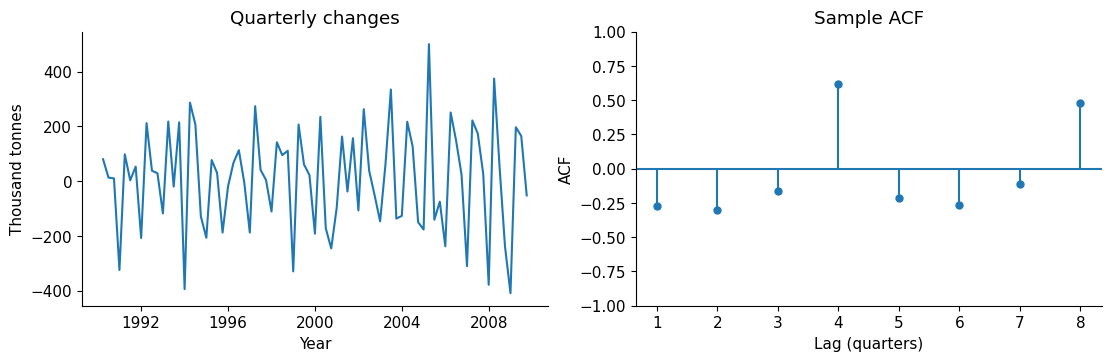

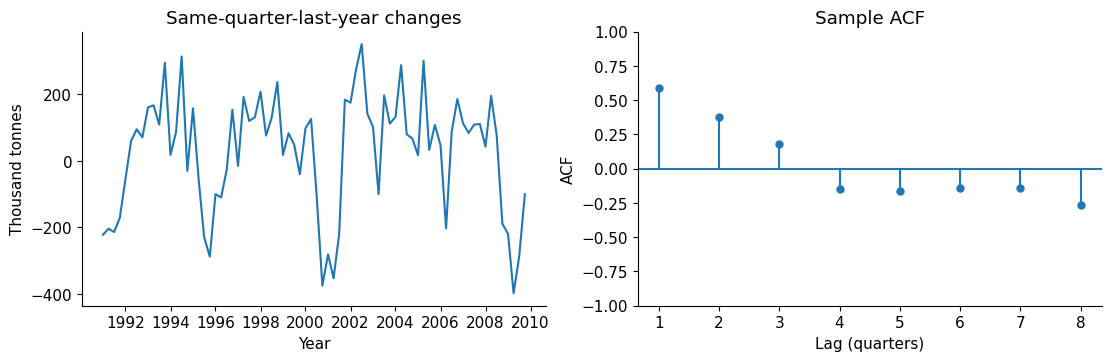

,lb_stat,lb_pvalue
8,54.937049,4.541058e-09


In [11]:
quarter_change = analysis.diff().dropna()
annual_change = analysis.diff(4).dropna()
display(pd.DataFrame({"Production": analysis, "Quarterly change": quarter_change,
                      "Annual change": annual_change}).loc["2007"].round(2))

# use company helper functions to plot dependence...
show_dependence(quarter_change, "Quarterly changes")
show_dependence(annual_change, "Same-quarter-last-year changes")

from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(annual_change, lags=[8], return_df=True)
display(lb)


**Manager’s comment:** Check that the ordinary and same-quarter-last-year differences answer the different questions their labels imply. Report both changes ending in 2007 Q1, explain what each measures, and verify the annual change against the observations being compared. Assess the annual changes using the time plot, ACF, and a joint statistical test of autocorrelations at lags 1–8. State the tested series, null, test statistic, and p-value. Interpret the result alongside the ACF and explain what the evidence establishes and its limits. Does your test result establish whether the annual-change series is stationary, or whether further differencing is needed? Explain.

> I found that the inherited notebook calculated the annual changes incorrectly because both series were defined using `analysis.diff()`. The correct same-quarter-last-year change is `analysis.diff(4)`.
> 
> The quarterly change ending in 2007 Q1 is **−311 thousand tonnes**, which measures the change from 2006 Q4 to 2007 Q1. The annual change ending in 2007 Q1 is **113 thousand tonnes**, which measures the change from 2006 Q1 to 2007 Q1. I verified the annual change directly: production increased from 2027 thousand tonnes in 2006 Q1 to 2140 thousand tonnes in 2007 Q1, a difference of 113 thousand tonnes.
> 
> The annual-change series appears less seasonal than the quarterly changes, but the ACF still shows substantial autocorrelation at several lags. A Ljung-Box test applied to the annual-change series through lag 8 produced a test statistic of **54.94** and a p-value of **4.54 × 10⁻⁹**. The null hypothesis is that the autocorrelations at lags 1 through 8 are jointly zero. Because the p-value is much smaller than 0.05, I reject the null and conclude that significant autocorrelation remains in the annual-change series.
> 
> This result provides evidence of dependence but does not establish whether the series is stationary or whether additional differencing is required. The Ljung-Box test only assesses autocorrelation, not stationarity itself, so additional analysis would be needed to answer those questions.

### Model Attempt

First a straight line, then a line through the decomposed trend with the quarterly effects added back. Both use the same time coordinate.

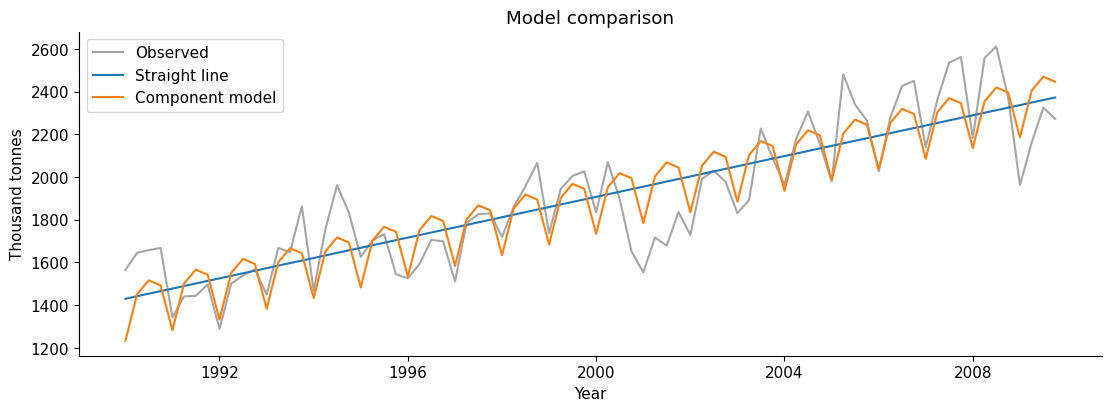

In [12]:
# Number quarters consecutively to give both regressions the same time coordinate.
time = pd.Series(np.arange(len(cement), dtype=float), index=cement.index, name="Quarter number")
# to_frame() supplies the two-dimensional input expected by sklearn.
X = time.loc[analysis.index].to_frame()
baseline = LinearRegression().fit(X, analysis)
# Omit dates where the centered decomposition has no trend estimate.
valid = decomposition.trend.notna()
trend_model = LinearRegression().fit(X.loc[valid], decomposition.trend.loc[valid])
baseline_values = pd.Series(baseline.predict(X), index=analysis.index)
trend_values = pd.Series(trend_model.predict(X), index=analysis.index)
# Look up the seasonal effect for each date by its calendar quarter.
seasonal_values = pd.Series(
    quarter_effects.reindex(analysis.index.quarter).to_numpy(), index=analysis.index
)
component_values = trend_values + seasonal_values

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(analysis.index, analysis, color="0.65", label="Observed")
ax.plot(baseline_values.index, baseline_values, label="Straight line")
ax.plot(component_values.index, component_values, label="Component model")
ax.set(title="Model comparison", xlabel="Year", ylabel="Thousand tonnes")
ax.legend()
plt.show()
plt.close(fig)

quarter
2006-10-01    2451.0
2007-01-01    2140.0
2007-04-01    2362.0
2007-07-01    2536.0
2007-10-01    2562.0
Freq: QS-JAN, Name: production_thousand_tonnes, dtype: float64

quarter
2008-01-01    2183.0
2008-04-01    2558.0
2008-07-01    2612.0
2008-10-01    2373.0
2009-01-01    1963.0
Freq: QS-JAN, Name: production_thousand_tonnes, dtype: float64

quarter
1   -158.658088
2     33.900735
3     77.687500
4     47.069853
dtype: float64

,MAE,RMSE,Mean error
Time-only,180.22,213.51,-40.4
Component,149.95,170.71,-25.7


,Time-only,Component
quarter,,
2008-01-01,-120.43,52.65
2008-04-01,242.33,222.93
2008-07-01,284.09,220.98
2008-10-01,32.84,0.44
2009-01-01,-389.40,-216.00
2009-04-01,-204.64,-223.72
2009-07-01,-51.89,-114.67
2009-10-01,-116.13,-148.22


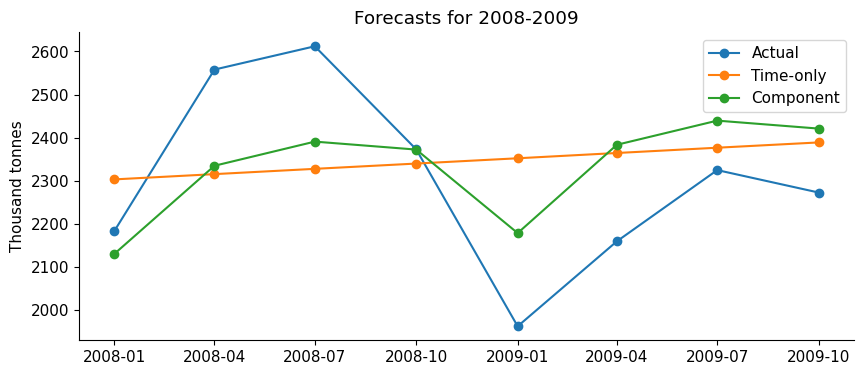

In [13]:
train = cement.loc[:'2007-10-01']
test = cement.loc['2008-01-01':]

display(train.tail())
display(test.head())

decomp_train = seasonal_decompose(
    train,
    model="additive",
    period=4
)

# manual seasonal effects
valid = decomp_train.trend.notna()

manual_trend = decomp_train.trend.dropna()

detrended = train.loc[manual_trend.index] - manual_trend

quarter_effects = detrended.groupby(
    detrended.index.quarter
).mean()

quarter_effects -= quarter_effects.mean()

display(quarter_effects)

time = pd.Series(
    np.arange(len(cement), dtype=float),
    index=cement.index,
    name="Quarter number"
)

X_train = time.loc[train.index].to_frame()
X_test = time.loc[test.index].to_frame()

# Time-only regression
baseline = LinearRegression()
baseline.fit(X_train, train)

# Component trend regression
trend_model = LinearRegression()
trend_model.fit(
    X_train.loc[valid],
    decomp_train.trend.loc[valid]
)

baseline_forecast = pd.Series(
    baseline.predict(X_test),
    index=test.index,
    name="Time-only"
)

trend_forecast = pd.Series(
    trend_model.predict(X_test),
    index=test.index
)

seasonal_forecast = pd.Series(
    quarter_effects.reindex(test.index.quarter).to_numpy(),
    index=test.index
)

component_forecast = pd.Series(
    trend_forecast + seasonal_forecast,
    index=test.index,
    name="Component"
)

predictions = pd.DataFrame({
    "Time-only": baseline_forecast,
    "Component": component_forecast
})

scores, errors = score_forecasts(test, predictions)

display(scores.round(2))
display(errors.round(2))

fig, ax = plt.subplots(figsize=(10,4))

ax.plot(test.index, test,
        marker='o',
        label='Actual')

ax.plot(
    baseline_forecast.index,
    baseline_forecast,
    marker='o',
    label='Time-only'
)

ax.plot(
    component_forecast.index,
    component_forecast,
    marker='o',
    label='Component'
)

ax.set(
    title="Forecasts for 2008-2009",
    ylabel="Thousand tonnes"
)

ax.legend()

plt.show()

**Manager’s comment:** Which observations were used to fit these models? Generate time-only regression and classical-component forecasts for the same eight withheld quarters of 2008–2009, using only information available through 2007 Q4. Compare MAE and RMSE, show actuals and forecasts together, and examine the direction or timing of errors as well as the averages. What assumptions about the future trend and seasonal pattern are built into the component forecast? Use your results to discuss where those assumptions may be questionable.

> The inherited models were fit using all observations from 1990-2009 because `analysis = cement`. That uses information from the evaluation period and is not a valid forecasting exercise. I rebuilt both models using only data through **2007 Q4** and evaluated forecasts on the eight withheld quarters from **2008-2009**.
> 
> The time-only regression forecasts a straight-line trend into the future, assuming production will continue to increase at a constant rate. The component forecast assumes both a linear trend and the historical quarterly seasonal pattern will continue unchanged. When evaluated on the withheld observations, the component model outperformed the time-only regression:
> 
> | Model | MAE | RMSE |
> | --- | :---: | :---: |
> | Time-only | 180.22 | 213.51 |
> | Component | 149.95 | 170.71 |
> 
> 
> The component model produced lower average and squared forecast errors, indicating that accounting for seasonality improved forecast accuracy. Both models tended to overpredict during 2009 (negative mean error), suggesting that actual production declined relative to the historical trend. Errors became especially large around 2009 Q1, when both models substantially missed the sharp drop in production. This suggests that extrapolating the historical trend and seasonal pattern may be questionable when economic conditions change. Although the component model performed better on this evaluation period, its forecasts rely on the assumption that both the trend and seasonal effects observed before 2008 remain stable into the future.

### Draft Recommendation

The analysis provides a robust, validated basis for the briefing. The component model follows the quarterly movements much better than the straight line, so it is the recommended forecasting approach. Seasonal effects explain the recurring variation, and the remaining changes show that the late-2006 decline was genuine. The model is ready to use for planning.

**Manager’s comment:** Correct unsupported claims in the inherited recommendation. Explain how decomposing or reconstructing observed production differs from demonstrating forecast accuracy, using evidence from your completed analysis. Then summarize the most important findings about recent activity and forecasting, give a recommendation supported by those findings and their limitations, and identify the next evidence needed before relying on the forecasts for planning. Your response is the completed briefing; refer to the results above rather than repeat the full analysis.

> The inherited recommendation overstates what the analysis demonstrates. Decomposing the historical series and reconstructing observed production shows that trend and seasonal components describe past behavior well, but that alone does not establish forecast accuracy. Forecast accuracy must be evaluated on data that were not used to fit the model.
> 
> The decomposition results show that cement production exhibits a long-term upward trend and a strong quarterly seasonal pattern. However, after correcting the seasonal-adjustment calculation and comparing classical decomposition with STL, the evidence for a substantial underlying decline from **2006 Q4** to **2007 Q1** became much *weaker*. The large observed drop was largely *explained by normal seasonal effects*, and STL suggested **almost no underlying** decline after seasonal adjustment.
> 
> Using only data through **2007 Q4**, the component forecast performed better than the time-only regression on the eight withheld quarters of **2008-2009**. The component model achieved lower error measures (**MAE = 149.95**, *RMSE = 170.71*) than the time-only model (**MAE = 180.22**, *RMSE = 213.51*), indicating that incorporating seasonality improved forecast accuracy during the evaluation period.
> 
> I recommend the component model over the time-only regression because it produced more accurate forecasts on the withheld data. However, *both models* substantially missed the sharp decline around **2009**, suggesting that the assumptions of a continuing linear trend and stable seasonal pattern may not hold during changing economic conditions. Before relying on these forecasts for planning, additional evidence is needed from a longer validation period and from forecasting methods that can better account for changing trends and economic shocks.

## Check and Submit

Submit one completed `.ipynb` containing the revised analysis, code, results, figures, responses to the manager explaining and verifying your changes, the completed briefing in Draft Recommendation, and assistance disclosure. You may reorganize the notebook; variable names and figure layouts need not match any reference. Preserve useful context, but do not leave unsupported inherited claims presented as your final conclusions. No separate CSV, report, or screenshot is required.

Restart the runtime and run the notebook in order. Retain outputs and check that your explanations agree with them. Download the completed `.ipynb` for submission.

|  Evaluation | Points |
| --- | ---: |
| Temporal patterns and decomposition interpretation | 1.0 |
| Seasonal adjustment, STL cross-check, and interpretation of changes | 2.5 |
| Joint dependence check and interpretation | 1.5 |
| Valid forecast comparison, error interpretation, and recommendation | 3.5 |
| Explanation and verification of consequential revisions | 1.0 |
| Reproducibility and assistance disclosure | 0.5 |
| **Total** | **10.0** |

**Assistance disclosure:** Identify material assistance, including AI use, and how you checked it, or write `None`.

> I used Copilot assistance to review the notebook, suggest code fixes, and help draft responses. I verified all code by running it and checked that conclusions matched the output tables and figures.

**Time Report (Required, Ungraded):** Approximately how much active time did you spend on this assignment, and which part required the most effort? Include relevant course-material review and notebook debugging; exclude separate study of general Python fundamentals.

> Approximately 3 hours. Most of the time was spent auditing the inherited notebook, fixing incorrect calculations, and validating the forecasting analysis.